In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## EDA

In [29]:
df = pd.read_csv('/kaggle/input/datasets/hamzahajjaji/diamonds/diamonds.csv')

display(df.head())
print("Dimensions :", df.shape)
df.info()
display(df.describe(include="all"))

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Dimensions : (50000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  object 
 2   color    50000 non-null  object 
 3   clarity  50000 non-null  object 
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.8+ MB


,carat,cut,color,clarity,depth,table,price,x,y,z
count,50000.000000,50000,50000,50000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
unique,NaN,5,7,8,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Ideal,G,SI1,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,19938,10452,12115,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.799444,NaN,NaN,NaN,61.753006,57.457830,3944.805440,5.734403,5.737956,3.541056
std,0.475173,NaN,NaN,NaN,1.431088,2.232092,3997.938105,1.123077,1.145579,0.707065
min,0.200000,NaN,NaN,NaN,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,NaN,NaN,NaN,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.700000,NaN,NaN,NaN,61.800000,57.000000,2410.000000,5.700000,5.710000,3.530000
75%,1.040000,NaN,NaN,NaN,62.500000,59.000000,5351.000000,6.540000,6.540000,4.040000


In [30]:
# les variables numériques et catégorielles
variables_numeriques = df.select_dtypes(include=np.number).columns.tolist()
variables_categorielles = df.select_dtypes(exclude=np.number).columns.tolist()

print("Variables numériques :", variables_numeriques)
print("Variables catégorielles :", variables_categorielles)

Variables numériques : ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
Variables catégorielles : ['cut', 'color', 'clarity']


In [31]:
# Valeurs manquantes et doublons
manquantes = df.isna().sum().sort_values(ascending=False)
display(manquantes[manquantes > 0])
print("Nombre de lignes dupliquées :", df.duplicated().sum())

Series([], dtype: int64)

Nombre de lignes dupliquées : 126


In [33]:
# Vérifier les valeurs uniques des variables caté
for col in variables_categorielles:
    print(f"\n{col} :", sorted(df[col].dropna().astype(str).unique()))


cut : ['Fair', 'Good', 'Ideal', 'Premium', 'Very Good']

color : ['D', 'E', 'F', 'G', 'H', 'I', 'J']

clarity : ['I1', 'IF', 'SI1', 'SI2', 'VS1', 'VS2', 'VVS1', 'VVS2']


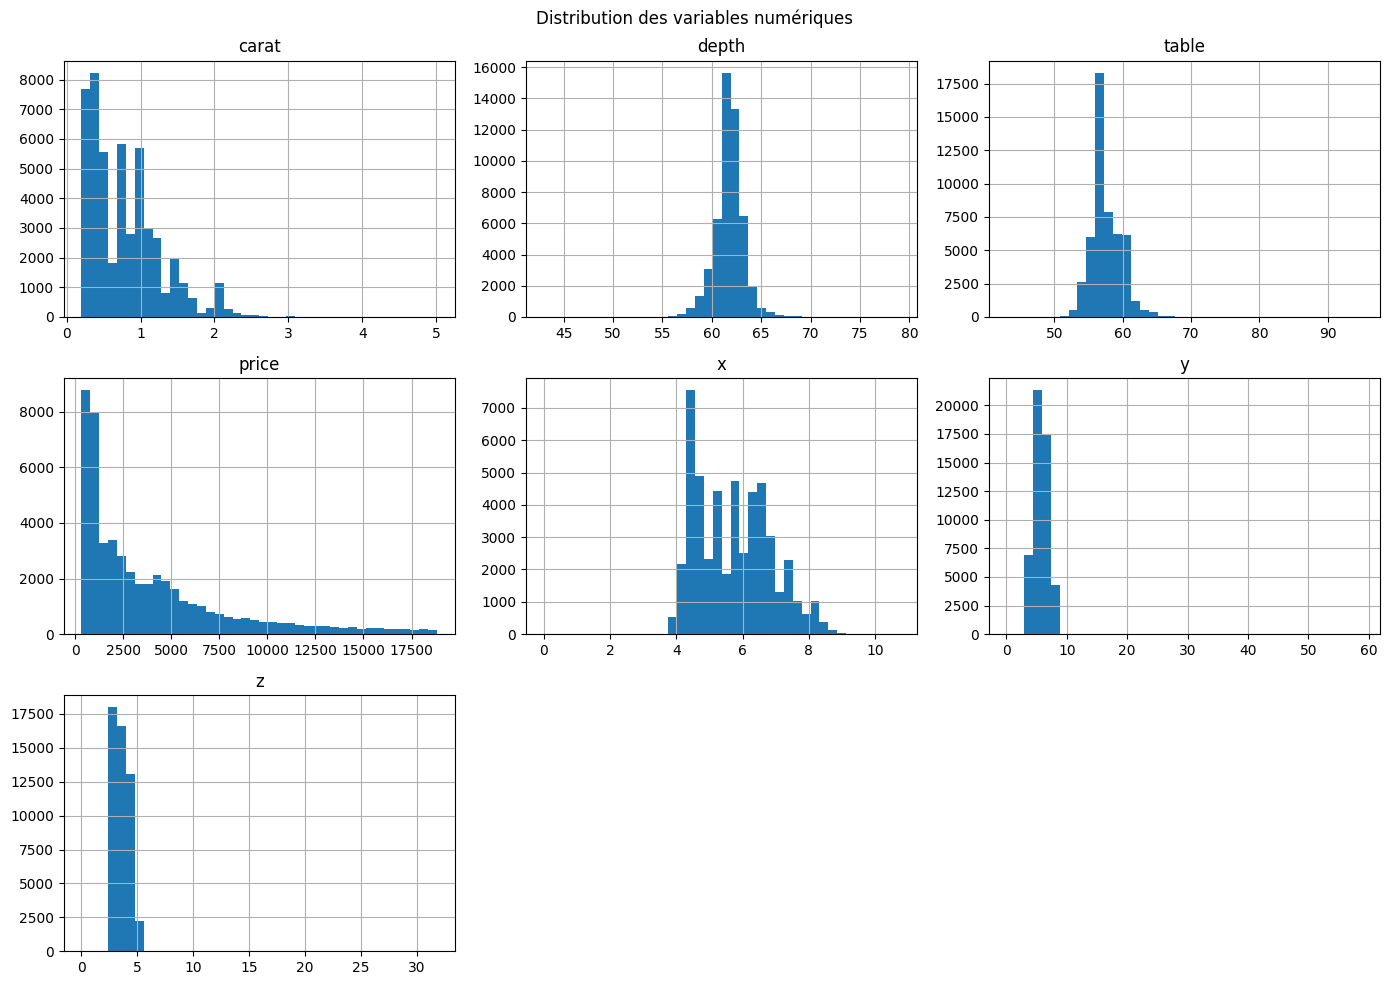

In [38]:
# Distributions des variables numériques
df[variables_numeriques].hist(figsize=(14, 10), bins=40)
plt.suptitle("Distribution des variables numériques")
plt.tight_layout()
plt.show()

In [ ]:
# Boxplots des variables numériques
for col in variables_numeriques:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.show()

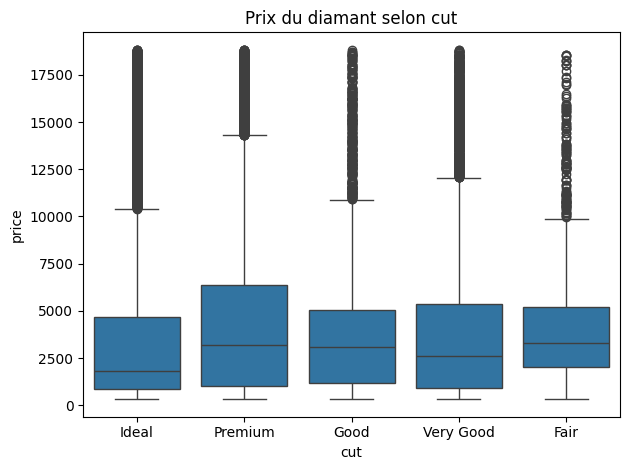

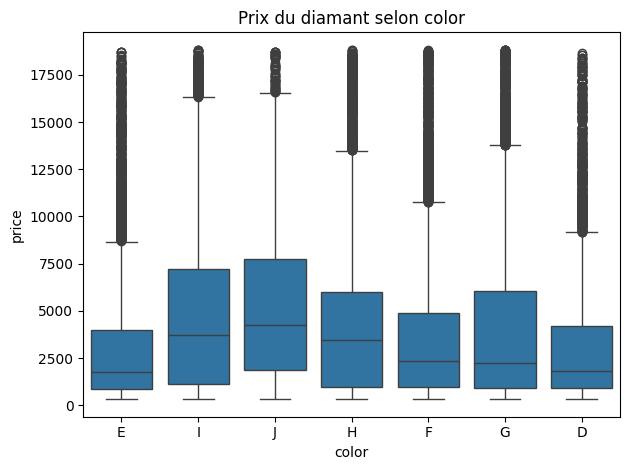

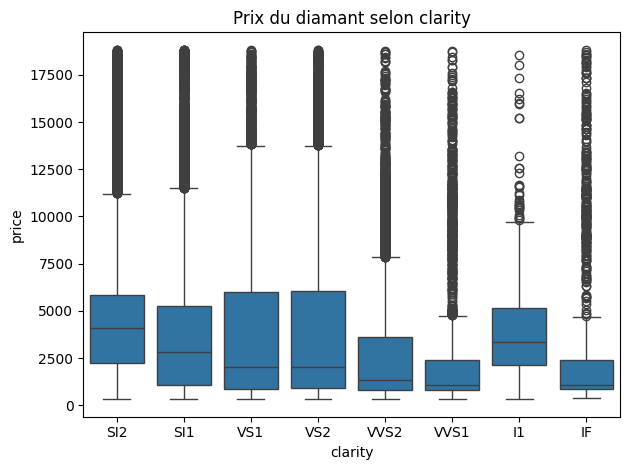

In [40]:
# Prix selon les variables catégorielles
for col in variables_categorielles:
    plt.figure()
    sns.boxplot(data=df, x=col, y="price")
    plt.title(f"Prix du diamant selon {col}")
    plt.tight_layout()
    plt.show()

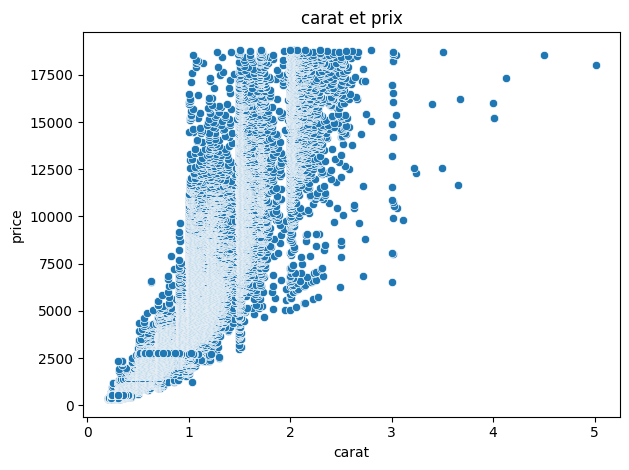

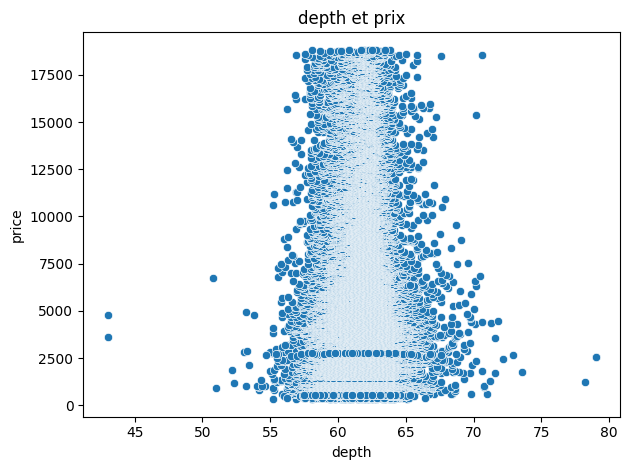

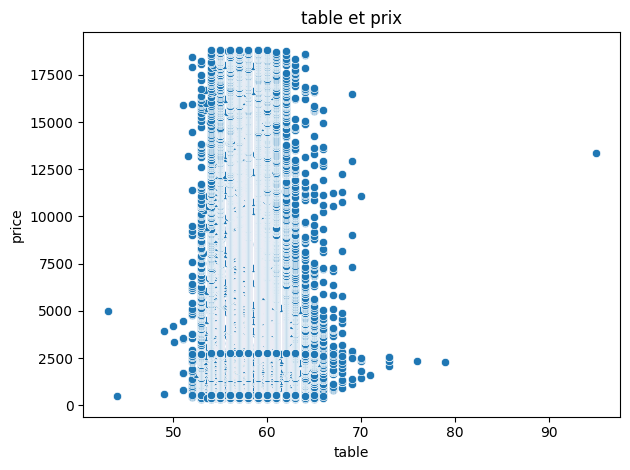

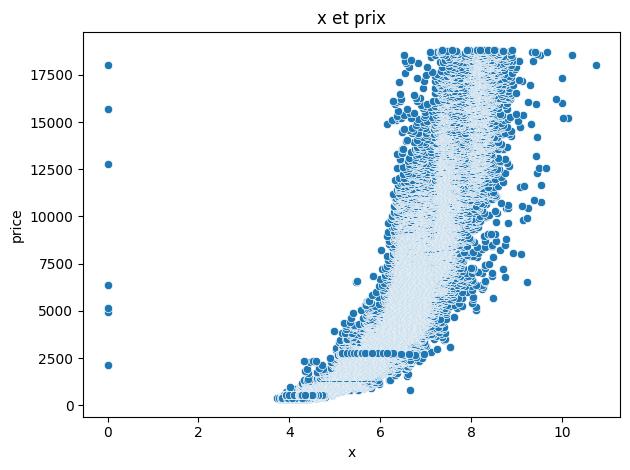

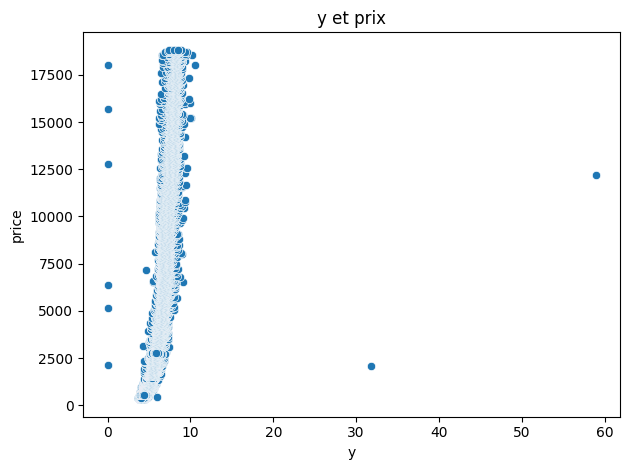

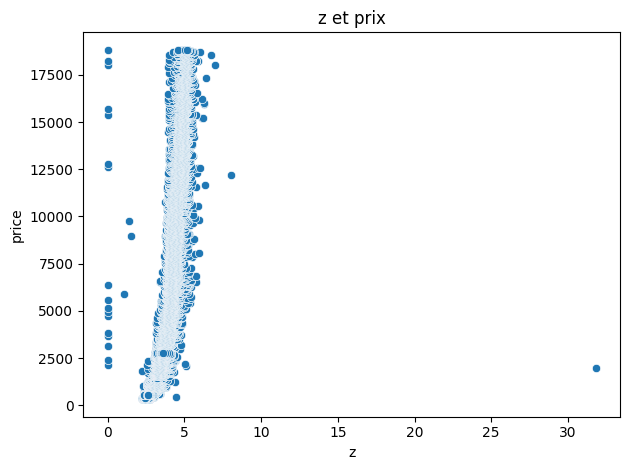

In [43]:
# Relations entre le prix et les mesures numériques
for col in [c for c in variables_numeriques if c != "price"]:
    plt.figure()
    sns.scatterplot(data=df, x=col, y="price")
    plt.title(f"{col} et prix")
    plt.tight_layout()
    plt.show()

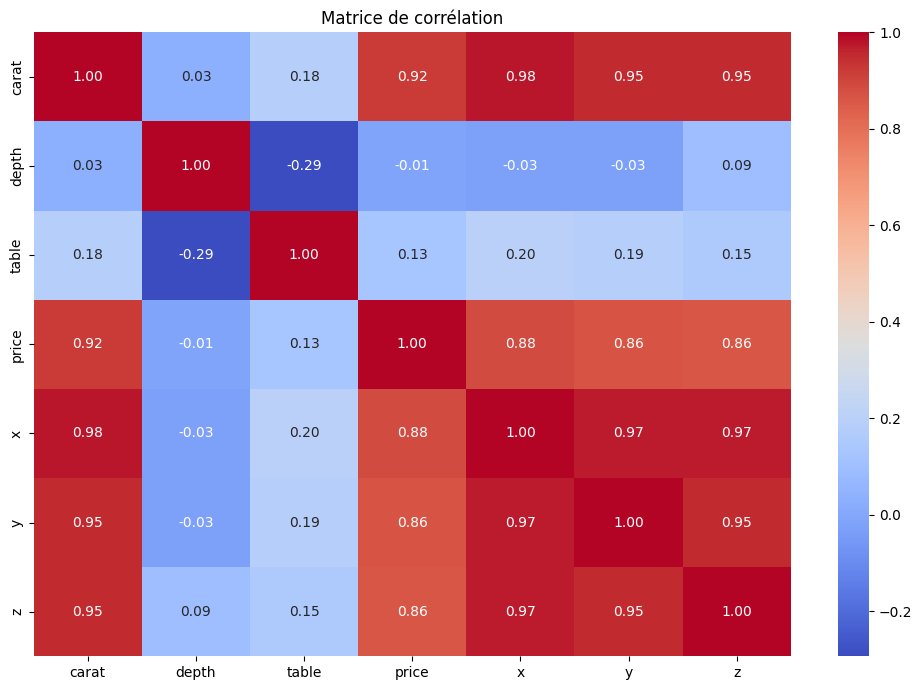

In [44]:
# Corrélations entre variables numériques
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[variables_numeriques].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

In [45]:
# Détection des valeurs aberrantes avec la méthode IQR
colonnes_iqr = [c for c in variables_numeriques if c != "price"]
resume_iqr = []

for col in colonnes_iqr:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    
    iqr = q3 - q1
    
    borne_basse = q1 - 1.5 * iqr
    borne_haute = q3 + 1.5 * iqr
    
    mask = ((df[col] < borne_basse) | (df[col] > borne_haute)).sum()
    
    resume_iqr.append({
        "variable": col,
        "borne_basse": borne_basse,
        "borne_haute": borne_haute,
        "count_outliers": int(mask)
    })

display(pd.DataFrame(resume_iqr))

,variable,borne_basse,borne_haute,count_outliers
0,carat,-0.560,2.000,1770
1,depth,58.750,64.750,2359
2,table,51.500,63.500,558
3,x,1.965,9.285,31
4,y,1.990,9.270,28
5,z,1.215,5.735,45


## Nettoyage des données

In [46]:
df_clean = df.copy()

# Supprimer les doublons exacts
nb_avant = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Doublons supprimés :", nb_avant - len(df_clean))

# les valeurs impossibles pour prix.
df_clean = df_clean[df_clean["price"] > 0]

print("Dimensions après nettoyage :", df_clean.shape)
display(df_clean.isna().sum().sort_values(ascending=False))
display(df_clean.describe(include="all").T)

Doublons supprimés : 126
Dimensions après nettoyage : (49874, 10)


carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
carat,49874.0,NaN,NaN,NaN,0.799331,0.474607,0.2,0.4,0.7,1.04,5.01
cut,49874,5,Ideal,19881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
color,49874,7,G,10424,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clarity,49874,8,SI1,12086,NaN,NaN,NaN,NaN,NaN,NaN,NaN
depth,49874.0,NaN,NaN,NaN,61.751803,1.428207,43.0,61.0,61.8,62.5,79.0
table,49874.0,NaN,NaN,NaN,57.458786,2.231087,43.0,56.0,57.0,59.0,95.0
price,49874.0,NaN,NaN,NaN,3945.384569,3996.939331,326.0,952.0,2414.0,5352.0,18823.0
x,49874.0,NaN,NaN,NaN,5.734441,1.12234,0.0,4.72,5.7,6.54,10.74
y,49874.0,NaN,NaN,NaN,5.73806,1.144973,0.0,4.72,5.71,6.54,58.9
z,49874.0,NaN,NaN,NaN,3.541028,0.706607,0.0,2.91,3.53,4.04,31.8


## Préparation des données

In [47]:
y = df_clean["price"]
X = df_clean.drop(columns=["price"])

# Ordre des cats
ordre_cut = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
ordre_color = ["J", "I", "H", "G", "F", "E", "D"]
ordre_clarity = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

ordres_possibles = {
    "cut": ordre_cut,
    "color": ordre_color,
    "clarity": ordre_clarity
}

# Les colomns
colonnes_ordinales = [c for c in ordres_possibles if c in X.columns]
colonnes_numeriques = X.select_dtypes(include=np.number).columns.tolist()
colonnes_categorielles = X.select_dtypes(exclude=np.number).columns.tolist()
colonnes_nominales = [c for c in colonnes_categorielles if c not in colonnes_ordinales]

print("Cible :", y.name)
print("Variables numériques :", colonnes_numeriques)
print("Variables ordinales :", colonnes_ordinales)
print("Variables nominales :", colonnes_nominales)
print("Variables explicatives :", X.columns.tolist())

Cible : price
Variables numériques : ['carat', 'depth', 'table', 'x', 'y', 'z']
Variables ordinales : ['cut', 'color', 'clarity']
Variables nominales : []
Variables explicatives : ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z']


## Séparation Train et Test

In [48]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=26
)

print("Train :", X_train.shape, y_train.shape)
print("Test  :", X_test.shape, y_test.shape)

Train : (39899, 9) (39899,)
Test  : (9975, 9) (9975,)


## Prétraitement des données

In [49]:
# numériques
preparation_numerique_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# nominales
preparation_nominale = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# ordinale
preparation_ordinal = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[ordres_possibles[c] for c in colonnes_ordinales]
    ))
])

transformations = []
if colonnes_numeriques:
    transformations.append(("numeriques", preparation_numerique_lr, colonnes_numeriques))
if colonnes_nominales:
    transformations.append(("nominales", preparation_nominale, colonnes_nominales))
if colonnes_ordinales:
    transformations.append(("ordinales", preparation_ordinal, colonnes_ordinales))

preprocesseur_lr = ColumnTransformer(transformers=transformations)

## Construction des pipelines

In [50]:
# Pipeline 1 : prétraitement + regression linéaire
pipeline_lr = Pipeline([
    ("preprocessing", preprocesseur_lr),
    ("modele", LinearRegression())
])

# Pour la forêt aléatoire, la standardisation n'est pas nécessaire.
preparation_numerique_rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

transformations_rf = []
if colonnes_numeriques:
    transformations_rf.append(("numeriques", preparation_numerique_rf, colonnes_numeriques))
if colonnes_nominales:
    transformations_rf.append(("nominales", preparation_nominale, colonnes_nominales))
if colonnes_ordinales:
    transformations_rf.append(("ordinales", preparation_ordinal, colonnes_ordinales))

preprocesseur_rf = ColumnTransformer(transformers=transformations_rf)

pipeline_rf = Pipeline([
    ("preprocessing", preprocesseur_rf),
    ("modele", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


## Entraînement des deux algorithmes

In [51]:
pipeline_lr.fit(X_train, y_train)
pipeline_rf.fit(X_train, y_train)

print("Les deux modèles sont entraînés.")

Les deux modèles sont entraînés.


## Validation croisée